In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
%matplotlib inline 

خب با سلام در ابتدا اومدیم داده های مربوط به اشخاص رو با عنوان heart_data برسی کردیم 


In [93]:
#نمایش داده ها و برسی کلی ستون ها
heart_data = pd.read_csv("16325569497737558.csv")
heart_data

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [94]:
heart_data.isnull().sum()

age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

In [95]:
heart_data['output'].value_counts()

output
1    165
0    138
Name: count, dtype: int64

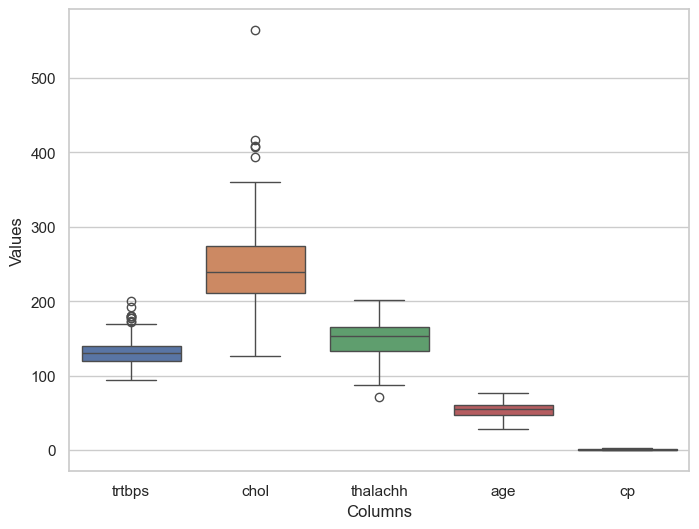

In [96]:
# رسم نمودار جعبه ای برای اینکه ببینم هر ستون چه میزان داده پرت داره
plt.figure(figsize=(8, 6))
sns.set_theme(style='whitegrid')
sns.boxplot(data=heart_data[["trtbps", "chol", "thalachh", "age", "cp"]])
plt.xlabel('Columns')
plt.ylabel('Values')
plt.show()

<Axes: ylabel='oldpeak'>

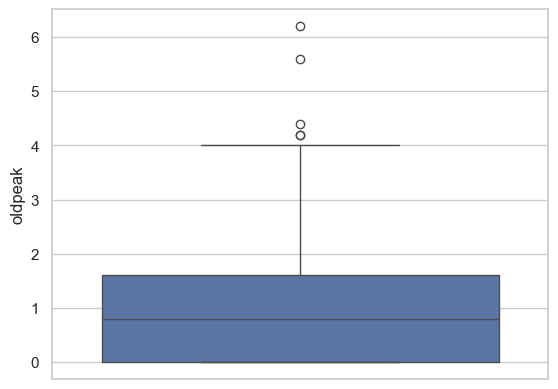

In [97]:
"""ستون oldpeak
متغیر هاش از 0 تا 6 باشه 
موارد حتی 4 و 5 خیلی نادر هستند ولی با اینحال جزو موارد مجاز توی داده های پرت به حساب میان"""
sns.boxplot(data=heart_data["oldpeak"])

In [98]:
""""متغیر های ستون cp 
به صورت ordinal هستند 
و فکر کردم که اگر ترتیب متغیر هارو عوض کنم شاید عملکرد مدل بهتر بشه که خب دقتش میشد 85"""
# heart_data["co"] = 3 - heart_data["cp"]

'"متغیر های ستون cp \nبه صورت ordinal هستند \nو فکر کردم که اگر ترتیب متغیر هارو عوض کنم شاید عملکرد مدل بهتر بشه که خب دقتش میشد 85'

اگه بخواییم خیلی کلی بگیم داده ها بدون مقادیر گمشده و مقادیر پیوسته هم داده پرت خیلی محدودی دارند که با استفاده از دو متد حذفشون کردیم

In [99]:
# متد percentile
def percentile(Data_Frame, Column):
    upper_limit = Data_Frame[Column].quantile(0.99)
    lower_limit = Data_Frame[Column].quantile(0.01)
    Data_Frame = Data_Frame.loc[
        (Data_Frame[Column] >= lower_limit) &
        (Data_Frame[Column] <= upper_limit)
    ]
    return Data_Frame

In [100]:
# متد IQR
def IQR(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_filtered

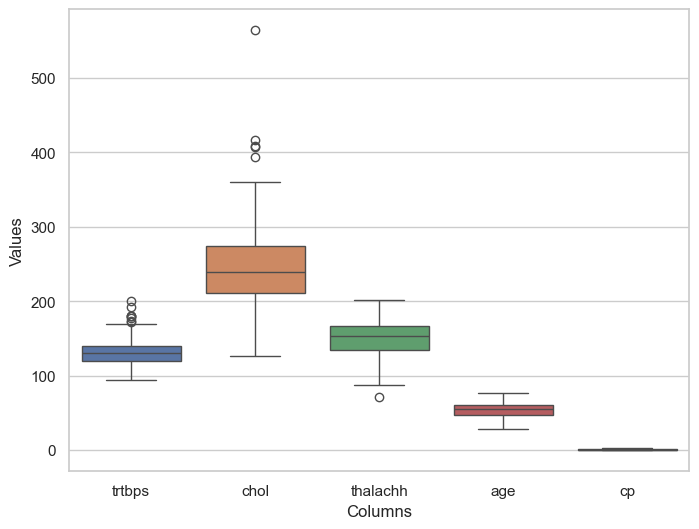

In [101]:
"""استفاده از توابع و برسی دوباره ستون هایی که مقادیر پیوسته دارند"""
heart_data_clean = percentile(heart_data, "chol")
heart_data_clean = IQR(heart_data_clean, "trtbps")
heart_data_clean = IQR(heart_data, "oldpeak")
plt.figure(figsize=(8, 6))
sns.set_theme(style='whitegrid')
sns.boxplot(data=heart_data_clean[["trtbps", "chol", "thalachh", "age", "cp"]])
plt.xlabel('Columns')
plt.ylabel('Values')
plt.show()

In [102]:
heart_data_clean

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


<Axes: ylabel='oldpeak'>

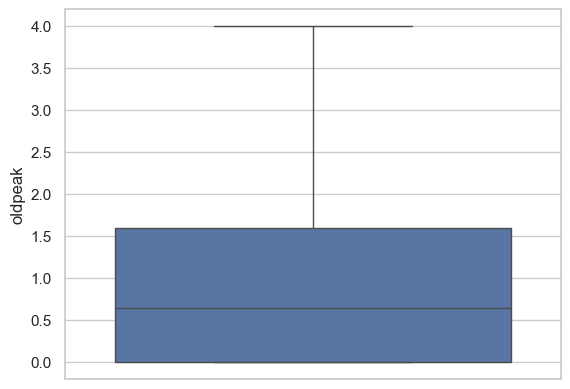

In [103]:
#### برسی دوباره ستون oldpeak
sns.boxplot(data=heart_data_clean["oldpeak"])

In [104]:
# جدا سازی داده ها 
X = np.asarray(heart_data_clean.drop('output', axis=1))
y = np.asarray(heart_data_clean['output'])

In [105]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [106]:
# آموزش مدل
Logestic_Regression = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, solver='liblinear').fit(X_train,y_train))
Logestic_Regression

,steps,"[('standardscaler', ...), ('logisticregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,0.01


In [115]:
Logestic_Regression.fit(X_train, y_train)
y_prob = Logestic_Regression.predict_proba(X_test)[:, 1]
threshold = 0.5
yhat = (y_prob >= threshold).astype(int)

In [116]:
from sklearn.metrics import classification_report, confusion_matrix
import itertools
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')
    print(cm)
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)
    fmt = '.2f' if normalize else 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
print(confusion_matrix(y_test, yhat, labels=[1,0]))

[[34  3]
 [ 4 19]]


Confusion matrix, without normalization
[[34  3]
 [ 4 19]]


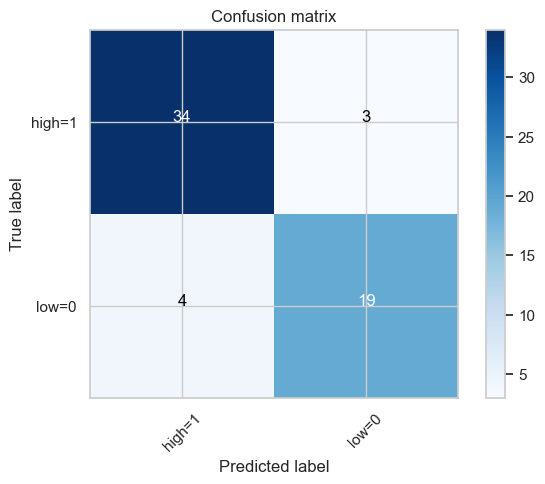

In [117]:
cnf_matrix = confusion_matrix(y_test, yhat, labels=[1,0])
np.set_printoptions(precision=2)
plt.figure()
plot_confusion_matrix(cnf_matrix, classes=['high=1','low=0'],normalize= False,  title='Confusion matrix')

In [118]:
# میزان دقت مدل
accuracy = accuracy_score(y_test, yhat)
accuracy

0.8833333333333333

خب نتیجه کار رو ملاحظه میکنید 
به نظرم اومد که اگه از accuracy استفاده کنم بهتره 
به جای اینکه بخوام از متد f1score استفاده کنم 
مدل تقریبا دقت بالایی داره منتها خب همونطور که توی ماتریس میبینید 3 مورد رو مدل پیش بینی کرده که احتمالا دچار حمله قلبی نشده باشند ولی اشتباه کرده 
به این دلیل رگرسیون لجستیک انتخاب شد این بود که میشه به راحتی یک آستانه رو تعیین کرد براش 
بستگی داره که چند درصد احتمال حمله قلبی رو باید جدی گرفت 
اگر آستانه بیاد روی 0.4 دقت مدل میرسه به 86 درصد ولی ایندفعه مواردی که مدل گفته احتمال حمله قلبی وجود نداره و اشتباه کرده به 1 عدد میرسه که خب این مدل خیلی بهتره از نظر من 
به هر حال امیدوارم که این پروژه براتون مفید بوده باشه
